In [2]:
import xarray as xr
import numpy as np
import cftime
import xesmf as xe
import TCs
import matplotlib.pyplot as plt
from scipy.stats import linregress
from scipy import stats
from scipy.signal import cheby1, filtfilt
import pandas as pd
import matplotlib as mpl

import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import cartopy.feature as cfeature
from cartopy.crs import PlateCarree, Robinson
from matplotlib.ticker import ScalarFormatter
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

import dask
dask.config.set({'array.slicing.split_large_chunks': True})
from scipy import stats

import json
import Plot

In [3]:
def lat_formatter(x, pos):
    hemi = 'N' if x > 0 else 'S' if x < 0 else ''
    return f"{abs(int(x))}°{hemi}"

def lon_formatter(x, pos):
    if x < 180:
        return f"{int(x)}°E"
    elif x == 180:
        return f"{int(x)}°"
    else:
        return f"{int(360-x)}°W"

In [4]:
ds = xr.open_dataset("Figure6.nc")

mask_hicam = ds.mask_hicam.sel(lon_hicam=slice(150, 270))
mask_sdcam = ds.mask_sdcam.sel(lon_sdcam=slice(150, 270))
mask_era5 = ds.mask_era5.sel(lon_era5=slice(150, 270))

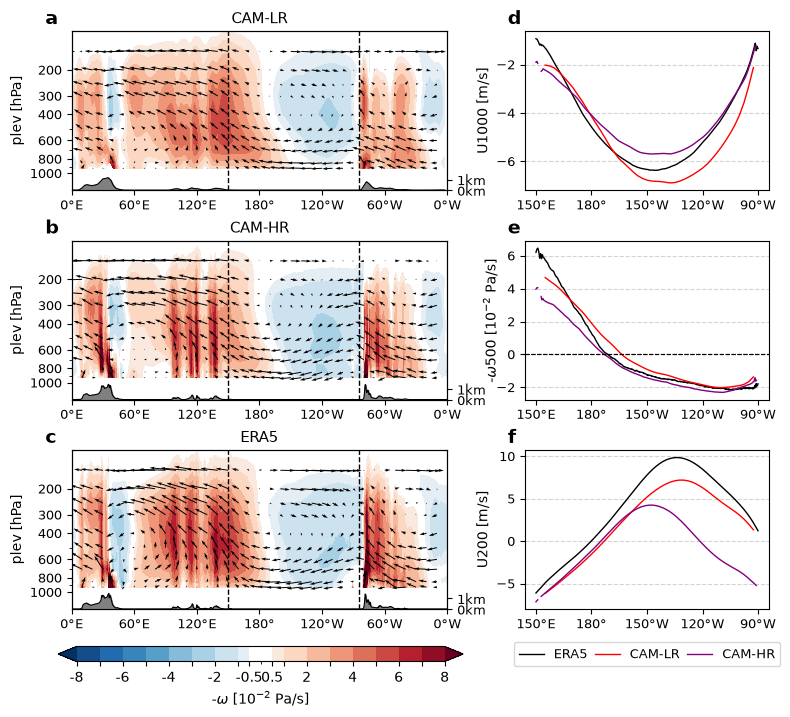

In [14]:
fig, axs = plt.subplots(ncols=2, nrows=3, figsize=(9,7.5), gridspec_kw={'width_ratios': [2, 1.3]})
plt.subplots_adjust(hspace=0.32, wspace=0.25)
lat_range = slice(-80, 80)
ratio = 100
cmap1, levels1, norm1 = Plot.def_colormap(max=8, white=0.5, interval=1, cmap='RdBu_r')
lonc = np.arange(0, 360+10, 10)
colors = {'hicam':'purple', 'sdcam':'red', }
legend_label = {'hicam':'CAM-HR', 'sdcam':'CAM-LR', }
numbers = [['a', 'd'], ['b', 'e'], ['c', 'f']]

for irow, res in enumerate(['sdcam', 'hicam']):
    Uclim = ds[f'uclim_{res}_hist']
    OMEGAclim = ds[f'omegaclim_{res}_hist']
    plev = Uclim[f'plev_{res}'][1:]/ratio
    X, Y = np.meshgrid(lonc, plev)
    cf2 = axs[irow][0].contourf(OMEGAclim[f'lon_{res}'], OMEGAclim[f'plev_{res}'][1:]/ratio, -OMEGAclim[1:,:]*100, 
                                cmap=cmap1, levels=levels1, norm=norm1, extend='both')
    axs[irow][0].quiver(X, Y, Uclim.interp({f'lon_{res}': lonc})[1:, :], -OMEGAclim.interp({f'lon_{res}': lonc})[1:, :]*100)
    ax2 = axs[irow][0].twinx()
    ax2.plot(ds[f'topo_{res}'][f'lon_{res}'], ds[f'topo_{res}'], color='k', linewidth=0.8)
    ax2.fill_between(ds[f'topo_{res}'][f'lon_{res}'], ds[f'topo_{res}'], 0, color='grey', )
    ax2.set_ylim(0,15)
    ax2.set_yticks([0, 1])
    ax2.set_yticklabels(['0km', '1km'])
    ax2.tick_params(labelsize=9)

Uclim = ds.uclim_era5_hist
OMEGAclim = ds.omegaclim_era5_hist
plev = Uclim['plev_era5'][1:]
X, Y = np.meshgrid(lonc, plev)
cf2 = axs[2][0].contourf(OMEGAclim['lon_era5'], OMEGAclim['plev_era5'][1:], -OMEGAclim[1:,:]*100, 
                            cmap=cmap1, levels=levels1, norm=norm1, extend='both')
axs[2][0].quiver(X, Y, Uclim.interp(lon_era5=lonc)[1:, :], -OMEGAclim.interp(lon_era5=lonc)[1:, :]*100)
ax2 = axs[2][0].twinx()
ax2.plot(ds.topo_era5.lon_era5, ds.topo_era5, color='k', linewidth=0.8)
ax2.fill_between(ds.topo_era5.lon_era5, ds.topo_era5, 0, color='grey', )
ax2.set_ylim(0,15)
ax2.set_yticks([0, 1])
ax2.set_yticklabels(['0km', '1km'])
ax2.tick_params(labelsize=9)

axs[0][1].plot(ds.walker_U1000_era5['lon_era5'].sel(lon_era5=slice(150, 270)), ds.walker_U1000_era5.sel(lon_era5=slice(150, 270)), 
               c='k', linestyle='solid', label='ERA5', linewidth=1.0)
axs[1][1].plot(ds.walker_OMEGA500_era5['lon_era5'].sel(lon_era5=slice(150, 270)), -ds.walker_OMEGA500_era5.sel(lon_era5=slice(150, 270))*100, 
               c='k', linestyle='solid', label='ERA5', linewidth=1.0)
axs[2][1].plot(ds.walker_U200_era5['lon_era5'].sel(lon_era5=slice(150, 270)), ds.walker_U200_era5.sel(lon_era5=slice(150, 270)), 
               c='k', linestyle='solid', label='ERA5', linewidth=1.0)

for irow, res in enumerate(['sdcam', 'hicam', ]):
    U1000 = ds[f'walker_U1000_{res}'].sel({f'lon_{res}': slice(150, 270)})
    U1000 = U1000.where(ds[f'mask_{res}'])
    axs[0][1].plot(U1000[f'lon_{res}'], U1000, color=colors[res], label=legend_label[res], linewidth=1.0)
    axs[0][1].set_ylabel(r'U1000 [m/s]')

    OMEGA500 = ds[f'walker_OMEGA500_{res}'].sel({f'lon_{res}': slice(150, 270)})
    OMEGA500 = OMEGA500.where(ds[f'mask_{res}'])
    axs[1][1].plot(OMEGA500[f'lon_{res}'], -OMEGA500*100, color=colors[res], label=legend_label[res], linewidth=1.0)
    axs[1][1].tick_params(labelsize=9)
    axs[1][1].set_ylabel(r'-$\omega$500 [10$^{-2}$ Pa/s]', labelpad=-2)
    axs[1][1].axhline(0, linewidth=0.8, linestyle='dashed', color='k')
    # axs[1][1].set_ylim(-3.5, 9)

    U200 = ds[f'walker_U200_{res}'].sel({f'lon_{res}': slice(150, 270)})
    U200 = U200.where(ds[f'mask_{res}'])
    axs[2][1].plot(U200[f'lon_{res}'], U200, color=colors[res], label=legend_label[res], linewidth=1.0)
    axs[2][1].set_ylabel(r'U200 [m/s]')

for irow, ax in enumerate(axs[:,0]):
    ax.axvline(150, color='k', linestyle='dashed', linewidth=1.0)
    ax.axvline(275, color='k', linestyle='dashed', linewidth=1.0)
    ax.invert_yaxis()
    ax.set_yscale('log')
    ax.set_ylabel('plev [hPa]')
    ax.set_xlim(0, 360)
    ax.set_ylim(1300, 110)
    ax.tick_params(labelsize=9)
    ax.set_xticks([0, 60, 120, 180, 240, 300, 360])
    ax.set_yticks([200, 300, 400, 600, 800, 1000])
    ax.get_yaxis().set_major_formatter(ScalarFormatter())
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lon_formatter))
    ax.annotate(
            numbers[irow][0], xy=(-0.07, 1.14), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top'
        )
for irow,ax in enumerate(axs[:,1]):
    ax.tick_params(labelsize=9)
    ax.set_xticks([150, 180, 210, 240, 270])
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lon_formatter))
    ax.grid(axis='y', linewidth=0.8, color='lightgrey', linestyle='dashed')
    ax.annotate(
            numbers[irow][1], xy=(-0.07, 1.14), xycoords='axes fraction', fontsize=14, fontweight='bold', ha='left', va='top'
        )

axs[1][0].set_title('CAM-HR', fontsize=11)
axs[0][0].set_title('CAM-LR', fontsize=11)
axs[2][0].set_title('ERA5', fontsize=11)

handles, labels = axs[2][1].get_legend_handles_labels()
leg = axs[2][1].legend(
    handles, labels, ncol=3, columnspacing=0.6,
    loc='lower center', bbox_to_anchor=(0.5, -0.4), fontsize=9, frameon=True)

cax = fig.add_axes([0.11, 0.04, 0.45, 0.02])  # [left, bottom, width, height] in figure coords
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap1, norm=norm1), 
                    cax=cax, orientation='horizontal', ticks=levels1[levels1 != 0], extend='both', spacing='proportional', 
                    label=r'-$\omega$ [10$^{-2}$ Pa/s]')
major_ticks = [-10, -8, -6, -4, -2, -0.5, 0.5, 2, 4, 6, 8, 10]
major_labels = [
    '' if t not in major_ticks else f'{t:g}'
    for t in levels1[levels1 != 0]
]
cbar.ax.set_xticklabels(major_labels);

plt.savefig(f'/home/yxia/figure/Walker_clim_hist.png', bbox_inches='tight', dpi=300)